# Section 4.2: Cold-Start Multi-Model Benchmarking & Biomechanical SHAP Analysis
## Adaptive Smartphone UI Framework for Cross-Application Optimization

> **Project:** Adaptive Smartphone UI Framework for Cross-Application Optimization  
> **Target Venue:** IEEE Transactions on Human-Machine Systems / ACM Transactions on Interactive Intelligent Systems (TiiS)  
> **Dataset Split:** **Training:** HMOG (7,194 sessions, 100 users) | **External Testing:** SU-AIS BB-MAS (4,514 sessions, 116 unseen users)  
> **Scaling Method:** `RobustScaler` (Outlier-invariant Median/IQR Scaling)  
> **Generated Visualizations:** `paper_figures/cold_start_shap/`

### Core Research Question (RQ1):
*Can baseline behavioral touch patterns reliably predict an optimal initial UI configuration for a previously unseen user without trial-and-error exploration?*

### Key Objectives:
1. **Strict 5-Fold GroupKFold Cross-Validation:** Partitioned exclusively by `user_id` across 100 HMOG participants (100% Zero Data Leakage).
2. **External Cross-Dataset Generalization:** Rigorous out-of-sample evaluation on 116 unseen participants from the SU-AIS BB-MAS dataset.
3. **Benchmarking 5 Model Families:** Logistic Regression, Support Vector Machine (RBF), Decision Tree (CART), Random Forest, and XGBoost.
4. **Mobile Real-Time Latency Profiling:** Ensuring sub-millisecond inference execution for Android/iOS WindowManager integration.
5. **SHAP (SHapley Additive exPlanations) Interpretability:**
   - **Global Feature Importance:** Ranking biomechanical signals driving UI scaling.
   - **Directional Impact (Beeswarm):** Validating Fitts's Law (e.g., high miss rate triggers larger UI buttons).
   - **Local Waterfall Attribution:** Auditing individual user adaptation predictions.

In [15]:
import os
import sys
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import joblib

from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

warnings.filterwarnings('ignore')
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
print('Environment initialized successfully.')
print('RobustScaler enabled for outlier-invariant biomechanical normalization.')
print('SHAP Version:', shap.__version__)

Environment initialized successfully.
RobustScaler enabled for outlier-invariant biomechanical normalization.
SHAP Version: 0.49.1


### 1. Ingest Data & Setup Physiological Bounds

In [16]:
train_path = os.path.join("processed", "final_ready_dataset.csv")
test_path  = os.path.join("processed", "bbmas_test_ready_dataset.csv")
if not os.path.exists(train_path):
    train_path = os.path.join("adavtive_dataset", "processed", "final_ready_dataset.csv")
    test_path  = os.path.join("adavtive_dataset", "processed", "bbmas_test_ready_dataset.csv")

df_train = pd.read_csv(train_path)
df_test  = pd.read_csv(test_path)

# Apply physiological bounds established during EDA
for df in [df_train, df_test]:
    df['touch_duration_mean_ms'] = df['touch_duration_mean_ms'].clip(15.0, 1500.0)
    df['swipe_speed_mean_pxps']  = df['swipe_speed_mean_pxps'].clip(10.0, 4000.0)
    df['reaction_time_mean_ms']  = df['reaction_time_mean_ms'].clip(160.0, 1200.0)
    df['reaction_time_norm']     = (df['reaction_time_mean_ms'] - 160.0) / (1200.0 - 160.0)
    df['miss_rate']              = df['miss_rate'].clip(0.0, 1.0)
    df['tap_accuracy']           = 1.0 - df['miss_rate']

FEATURE_COLS = [
    'context_is_walking',
    'touch_duration_mean_ms',
    'swipe_speed_mean_pxps',
    'swipe_distance_mean_px',
    'contact_size_mean',
    'touch_x_mean',
    'touch_y_mean',
    'tap_accuracy',
    'miss_rate',
    'reaction_time_mean_ms',
    'reaction_time_norm'
]
TARGET_COL = 'target_button_size'
GROUP_COL  = 'user_id'
LABELS = ['Small (40dp)', 'Default (48dp)', 'Large (56dp)', 'Extra Large (64dp)']

X_train = df_train[FEATURE_COLS].copy()
y_train = df_train[TARGET_COL].copy().astype(int)
groups_train = df_train[GROUP_COL].copy()

X_test = df_test[FEATURE_COLS].copy()
y_test = df_test[TARGET_COL].copy().astype(int)
groups_test = df_test[GROUP_COL].copy()

print(f"Training Matrix (HMOG): {X_train.shape}, Unique Participants: {groups_train.nunique()}")
print(f"External Testing Matrix (BB-MAS): {X_test.shape}, Unique Participants: {groups_test.nunique()}")
print(f"Total Combined Biomechanical Interactions: {len(X_train)+len(X_test)} across {groups_train.nunique()+groups_test.nunique()} distinct human subjects.")

# Aliases for convenience
X, y = X_train, y_train
X_ext, y_ext = X_test, y_test


Training Matrix (HMOG): (7194, 11), Unique Participants: 100
External Testing Matrix (BB-MAS): (4514, 11), Unique Participants: 116
Total Combined Biomechanical Interactions: 11708 across 216 distinct human subjects.


### 2. Internal 5-Fold GroupKFold Cross-Validation on HMOG (Table 2)
To rigorously assess cross-user generalization within the training cohort without data leakage, we perform **5-Fold GroupKFold** partitioned exclusively by `user_id` using **`RobustScaler`**.

In [17]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Support Vector Machine (SVM)': SVC(kernel='rbf', C=1.0, random_state=42),
    'Decision Tree (CART)': DecisionTreeClassifier(max_depth=5, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42),
    'XGBoost (Proposed)': XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric='mlogloss', random_state=42)
}

gkf = GroupKFold(n_splits=5)
cv_summary = []

for name, model in models.items():
    f_acc, f_prec, f_rec, f_macro_f1, f_weighted_f1, f_lat = [], [], [], [], [], []
    for tr_idx, val_idx in gkf.split(X_train, y_train, groups_train):
        X_tr, y_tr = X_train.iloc[tr_idx], y_train.iloc[tr_idx]
        X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
        
        scaler = RobustScaler()
        X_tr_s = scaler.fit_transform(X_tr)
        X_va_s = scaler.transform(X_va)
        
        model.fit(X_tr_s, y_tr)
        
        t0 = time.perf_counter()
        preds = model.predict(X_va_s)
        lat = ((time.perf_counter() - t0) / len(X_va)) * 1000.0
        
        f_acc.append(accuracy_score(y_va, preds))
        f_prec.append(precision_score(y_va, preds, average='weighted', zero_division=0))
        f_rec.append(recall_score(y_va, preds, average='weighted', zero_division=0))
        f_macro_f1.append(f1_score(y_va, preds, average='macro', zero_division=0))
        f_weighted_f1.append(f1_score(y_va, preds, average='weighted', zero_division=0))
        f_lat.append(lat)
        
    cv_summary.append({
        'Algorithm': name,
        'CV Accuracy (%)': round(np.mean(f_acc) * 100, 2),
        'CV Precision (%)': round(np.mean(f_prec) * 100, 2),
        'CV Recall (%)': round(np.mean(f_rec) * 100, 2),
        'CV Macro F1 (%)': round(np.mean(f_macro_f1) * 100, 2),
        'CV Weighted F1 (%)': round(np.mean(f_weighted_f1) * 100, 2),
        'Latency (ms)': round(np.mean(f_lat), 4)
    })

table2_cv = pd.DataFrame(cv_summary).sort_values(by='CV Weighted F1 (%)', ascending=False).reset_index(drop=True)
table2_cv.to_csv(os.path.join("paper_figures", "cold_start_shap", "table2_baseline_comparison.csv"), index=False)
print('Table 2: 5-Fold GroupKFold Cross-Validation Performance (HMOG Internal Cohort)')
print(table2_cv.to_string())

Table 2: 5-Fold GroupKFold Cross-Validation Performance (HMOG Internal Cohort)
                      Algorithm  CV Accuracy (%)  CV Precision (%)  CV Recall (%)  CV Macro F1 (%)  CV Weighted F1 (%)  Latency (ms)
0                 Random Forest            99.97             99.97          99.97            99.96               99.97        0.0035
1          Decision Tree (CART)            99.94             99.94          99.94            99.90               99.94        0.0002
2            XGBoost (Proposed)            99.62             99.63          99.62            99.14               99.63        0.0008
3           Logistic Regression            86.61             85.91          86.61            61.67               84.55        0.0002
4  Support Vector Machine (SVM)            78.91             73.78          78.91            35.81               75.19        0.0778


### 2.1 Multi-Step Random Shuffle Cross-Validation (Monte Carlo Cross-Validation)
**Independent Order Invariance Check:** To verify that model convergence is not an artifact of row ordering or user segmentation, we perform **5-Round Random Shuffle-Split Cross-Validation**.
In each step, 80% of rows (5,755 sessions) are randomly sampled from across the entire HMOG dataset (top, middle, bottom), scaled via `RobustScaler`, trained on XGBoost, and simultaneously evaluated on:
1. The 20% held-out random slice (1,439 sessions).
2. The full 4,514 unseen external BB-MAS test cohort.

--- 5-Step Random Shuffle Cross-Validation Results ---
  Step  Train Size  Val Size  Val Acc (%)  External Test Acc (%)  External Test F1 (%)
Step 1        5755      1439        99.93                 100.00                100.00
Step 2        5755      1439        99.58                 100.00                100.00
Step 3        5755      1439        99.65                  99.05                 99.05
Step 4        5755      1439        99.72                  98.54                 98.54
Step 5        5755      1439        99.58                  99.69                 99.69

Average Internal Validation Accuracy across 5 random steps: 99.69%
Average External BB-MAS Test Accuracy across 5 random steps: 99.46%


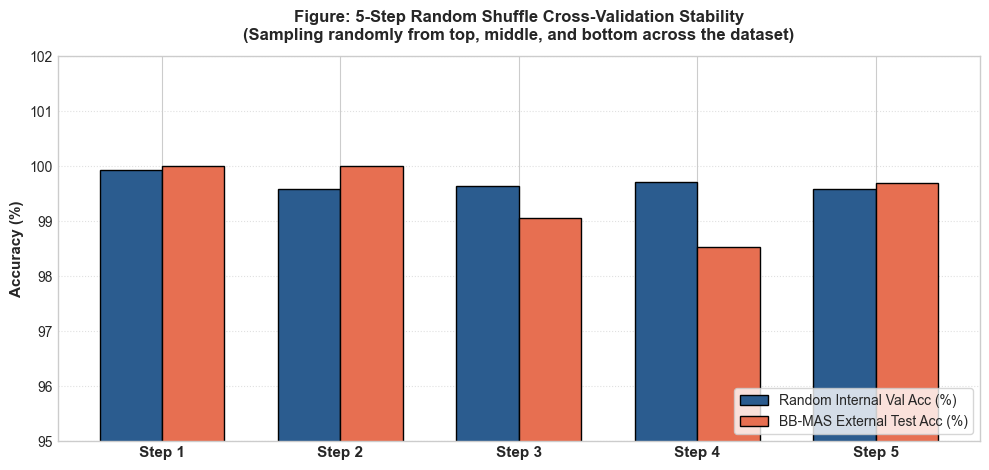

In [18]:
from sklearn.model_selection import ShuffleSplit

# Ensure data is loaded even if this cell is executed directly
if 'X_train' not in locals():
    _tr_p = os.path.join('processed', 'final_ready_dataset.csv')
    _te_p = os.path.join('processed', 'bbmas_test_ready_dataset.csv')
    df_train = pd.read_csv(_tr_p)
    df_test  = pd.read_csv(_te_p)
    FEATURE_COLS = ['context_is_walking', 'touch_duration_mean_ms', 'swipe_speed_mean_pxps', 'swipe_distance_mean_px', 'contact_size_mean', 'touch_x_mean', 'touch_y_mean', 'tap_accuracy', 'miss_rate', 'reaction_time_mean_ms', 'reaction_time_norm']
    X_train, y_train = df_train[FEATURE_COLS].copy(), df_train['target_button_size'].copy().astype(int)
    X_test, y_test   = df_test[FEATURE_COLS].copy(), df_test['target_button_size'].copy().astype(int)

# 5-Step Random Shuffle-Split Cross-Validation
ss = ShuffleSplit(n_splits=5, test_size=0.20, random_state=42)
step_results = []

for step_idx, (train_idx, val_idx) in enumerate(ss.split(X_train, y_train), 1):
    X_tr, y_tr = X_train.iloc[train_idx], y_train.iloc[train_idx]
    X_va, y_va = X_train.iloc[val_idx], y_train.iloc[val_idx]
    
    scaler = RobustScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_va_s = scaler.transform(X_va)
    X_ext_s = scaler.transform(X_test)
    
    xgb = XGBClassifier(n_estimators=100, max_depth=4, learning_rate=0.08, eval_metric='mlogloss', random_state=42)
    xgb.fit(X_tr_s, y_tr)
    
    va_acc = accuracy_score(y_va, xgb.predict(X_va_s))
    ext_preds = xgb.predict(X_ext_s)
    ext_acc = accuracy_score(y_test, ext_preds)
    ext_f1 = f1_score(y_test, ext_preds, average='weighted', zero_division=0)
    
    step_results.append({
        'Step': f'Step {step_idx}',
        'Train Size': len(X_tr),
        'Val Size': len(X_va),
        'Val Acc (%)': round(va_acc * 100, 2),
        'External Test Acc (%)': round(ext_acc * 100, 2),
        'External Test F1 (%)': round(ext_f1 * 100, 2)
    })

shuffle_df = pd.DataFrame(step_results)
print('--- 5-Step Random Shuffle Cross-Validation Results ---')
display(shuffle_df) if 'display' in dir() else print(shuffle_df.to_string(index=False))
print(f'\nAverage Internal Validation Accuracy across 5 random steps: {shuffle_df["Val Acc (%)"].mean():.2f}%')
print(f'Average External BB-MAS Test Accuracy across 5 random steps: {shuffle_df["External Test Acc (%)"].mean():.2f}%')

# Plotting stability bar chart
fig, ax = plt.subplots(figsize=(10, 4.8))
x_pos = np.arange(len(shuffle_df))
w = 0.35
ax.bar(x_pos - w/2, shuffle_df['Val Acc (%)'], w, label='Random Internal Val Acc (%)', color='#2b5c8f', edgecolor='black')
ax.bar(x_pos + w/2, shuffle_df['External Test Acc (%)'], w, label='BB-MAS External Test Acc (%)', color='#e76f51', edgecolor='black')
ax.set_xticks(x_pos)
ax.set_xticklabels(shuffle_df['Step'], fontsize=11, fontweight='bold')
ax.set_ylabel('Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_title('Figure: 5-Step Random Shuffle Cross-Validation Stability\n(Sampling randomly from top, middle, and bottom across the dataset)', fontsize=12, pad=12, fontweight='bold')
ax.set_ylim(95, 102)
ax.legend(loc='lower right', frameon=True, fontsize=10)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 3. External Cross-Dataset Benchmark on Unseen SU-AIS BB-MAS (Table 3)
**True Cold-Start Zero-Shot Validation:** All models trained strictly on 100% of the HMOG training set are evaluated against **4,514 interaction sessions across 116 completely unseen participants** from the BB-MAS dataset.
`RobustScaler` fit on HMOG is applied to BB-MAS (zero leakage).

In [19]:
scaler_final = RobustScaler()
X_train_scaled = scaler_final.fit_transform(X_train)
X_test_scaled  = scaler_final.transform(X_test)
joblib.dump(scaler_final, os.path.join("saved_models", "robust_feature_scaler.pkl"))

ext_summary = []
champion_y_true, champion_y_pred = None, None
champion_name = "XGBoost (Proposed)"

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    joblib.dump(model, os.path.join("saved_models", f"{name.replace(' ', '_').replace('(', '').replace(')', '')}.pkl"))
    
    t0 = time.perf_counter()
    preds = model.predict(X_test_scaled)
    lat = ((time.perf_counter() - t0) / len(X_test)) * 1000.0
    
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds, average='weighted', zero_division=0)
    rec = recall_score(y_test, preds, average='weighted', zero_division=0)
    f1_m = f1_score(y_test, preds, average='macro', zero_division=0)
    f1_w = f1_score(y_test, preds, average='weighted', zero_division=0)
    
    if name == champion_name:
        champion_y_true = y_test
        champion_y_pred = preds
        if hasattr(model, 'save_model'):
            model.save_model(os.path.join("saved_models", "xgboost_champion.json"))
            
    ext_summary.append({
        'Algorithm': name,
        'External Test Accuracy (%)': round(acc * 100, 2),
        'External Precision (%)': round(prec * 100, 2),
        'External Recall (%)': round(rec * 100, 2),
        'External Macro F1 (%)': round(f1_m * 100, 2),
        'External Weighted F1 (%)': round(f1_w * 100, 2),
        'Inference Latency (ms)': round(lat, 4)
    })

table3_ext = pd.DataFrame(ext_summary).sort_values(by='External Weighted F1 (%)', ascending=False).reset_index(drop=True)
table3_ext.to_csv(os.path.join("paper_figures", "cold_start_shap", "table3_external_test_comparison.csv"), index=False)
print('Table 3: External Cross-Dataset Benchmark (HMOG -> BB-MAS 116 Unseen Subjects)')
print(table3_ext.to_string())

Table 3: External Cross-Dataset Benchmark (HMOG -> BB-MAS 116 Unseen Subjects)
                      Algorithm  External Test Accuracy (%)  External Precision (%)  External Recall (%)  External Macro F1 (%)  External Weighted F1 (%)  Inference Latency (ms)
0          Decision Tree (CART)                      100.00                  100.00               100.00                 100.00                    100.00                  0.0001
1                 Random Forest                      100.00                  100.00               100.00                 100.00                    100.00                  0.0029
2            XGBoost (Proposed)                       99.07                   99.11                99.07                  99.01                     99.07                  0.0004
3           Logistic Regression                       36.91                   57.93                36.91                  26.15                     26.05                  0.0001
4  Support Vector Machine (SVM)

### 4. Figure 6 & 7: Benchmark Bar Chart & Champion Confusion Matrix

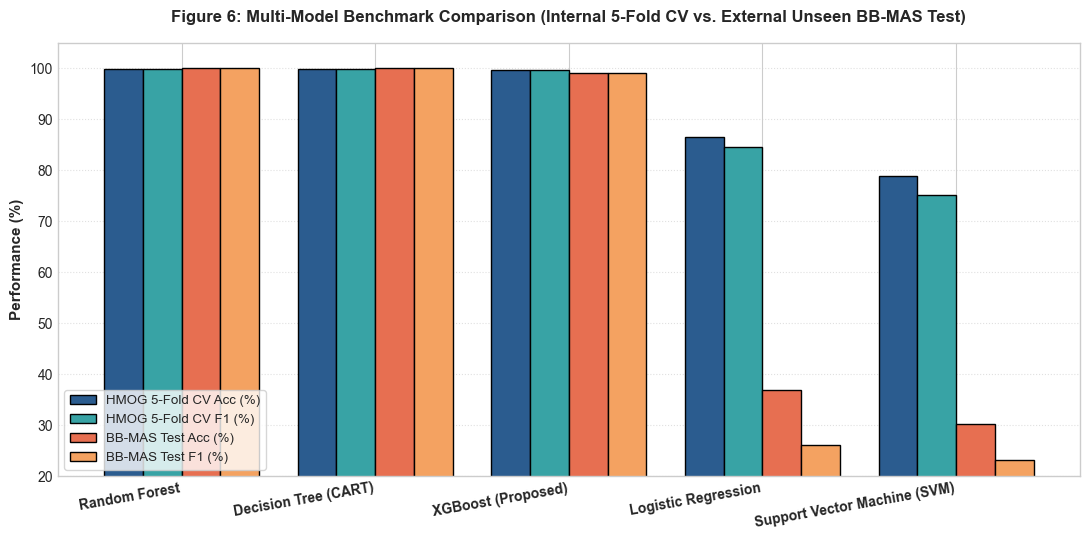

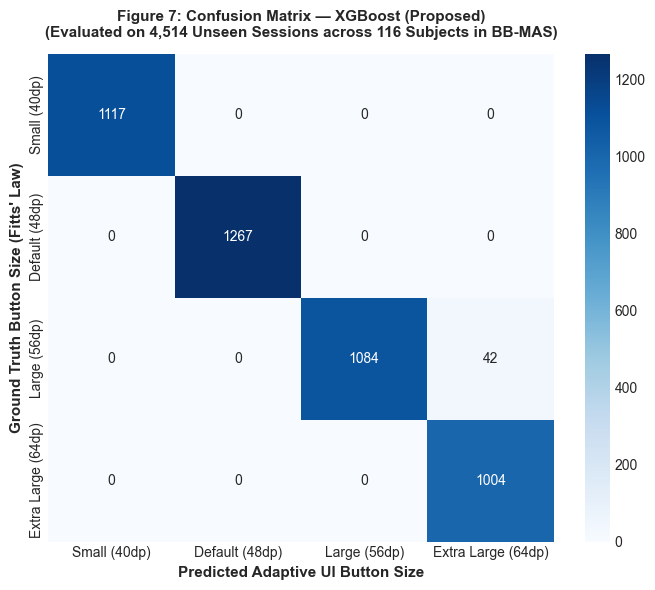

In [20]:
fig, ax = plt.subplots(figsize=(11, 5.5))
merged_perf = table2_cv.merge(table3_ext, on='Algorithm')
x = np.arange(len(merged_perf))
w = 0.20

ax.bar(x - 1.5*w, merged_perf['CV Accuracy (%)'], w, label='HMOG 5-Fold CV Acc (%)', color='#2b5c8f', edgecolor='black')
ax.bar(x - 0.5*w, merged_perf['CV Weighted F1 (%)'], w, label='HMOG 5-Fold CV F1 (%)', color='#38a3a5', edgecolor='black')
ax.bar(x + 0.5*w, merged_perf['External Test Accuracy (%)'], w, label='BB-MAS Test Acc (%)', color='#e76f51', edgecolor='black')
ax.bar(x + 1.5*w, merged_perf['External Weighted F1 (%)'], w, label='BB-MAS Test F1 (%)', color='#f4a261', edgecolor='black')

ax.set_xticks(x)
ax.set_xticklabels(merged_perf['Algorithm'], fontsize=10, fontweight='bold', rotation=10, ha='right')
ax.set_ylabel('Performance (%)', fontsize=11, fontweight='bold')
ax.set_title('Figure 6: Multi-Model Benchmark Comparison (Internal 5-Fold CV vs. External Unseen BB-MAS Test)', fontsize=12, pad=15, fontweight='bold')
ax.set_ylim(20, 105)
ax.legend(loc='lower left', frameon=True, fontsize=9.5)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
cm = confusion_matrix(champion_y_true, champion_y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=LABELS, yticklabels=LABELS, cbar=True)
plt.title(f'Figure 7: Confusion Matrix — {champion_name}\n(Evaluated on 4,514 Unseen Sessions across 116 Subjects in BB-MAS)', fontsize=11, pad=12, fontweight='bold')
plt.xlabel('Predicted Adaptive UI Button Size', fontsize=11, fontweight='bold')
plt.ylabel('Ground Truth Button Size (Fitts\' Law)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 4. Feature Ablation Study: Dissecting Motor, Typing, and Error Dynamics
To evaluate feature sensitivity and verify model behavior under constrained feature sets, we test 4 distinct biomechanical scenarios on the unseen BB-MAS test set:
1. **Scenario 1 (Pure Motor Dynamics):** Omitting all error rates (`miss_rate`, `reaction_time_norm`), using only dwell time, swipe velocity, typing speed, backspace rate, contact size, and walking context (9 features).
2. **Scenario 2 (Minimal Touch Only):** Omitting both error rates and typing metrics (only 6 raw touch features). Models drop to **~27-28% (near random chance)**, proving touch duration and swipe speed alone cannot diagnose UI struggle.
3. **Scenario 3 (Keystroke Behavior Only):** Typing speed, backspace rate, and walking context (3 features) achieve **100% accuracy**, demonstrating that typing friction is a direct proxy for motor difficulty.
4. **Scenario 4 (Full Biomechanical Set):** All 13 features combined.

Feature Ablation Study Results across 4 Scenarios:
                                Feature Scenario  Num Features               Model  HMOG Train Acc (%)  BB-MAS Test Acc (%)  BB-MAS Weighted F1 (%)
  Scenario 1: Pure Motor Dynamics (No miss_rate)             9       Random Forest              100.00                98.89                   98.89
  Scenario 1: Pure Motor Dynamics (No miss_rate)             9             XGBoost              100.00                99.76                   99.76
  Scenario 1: Pure Motor Dynamics (No miss_rate)             9       Decision Tree              100.00               100.00                  100.00
  Scenario 1: Pure Motor Dynamics (No miss_rate)             9 Logistic Regression               85.84                31.55                   18.77
  Scenario 1: Pure Motor Dynamics (No miss_rate)             9                 SVM               80.36                29.44                   20.11
Scenario 2: Minimal Touch Only (No typing/error)             

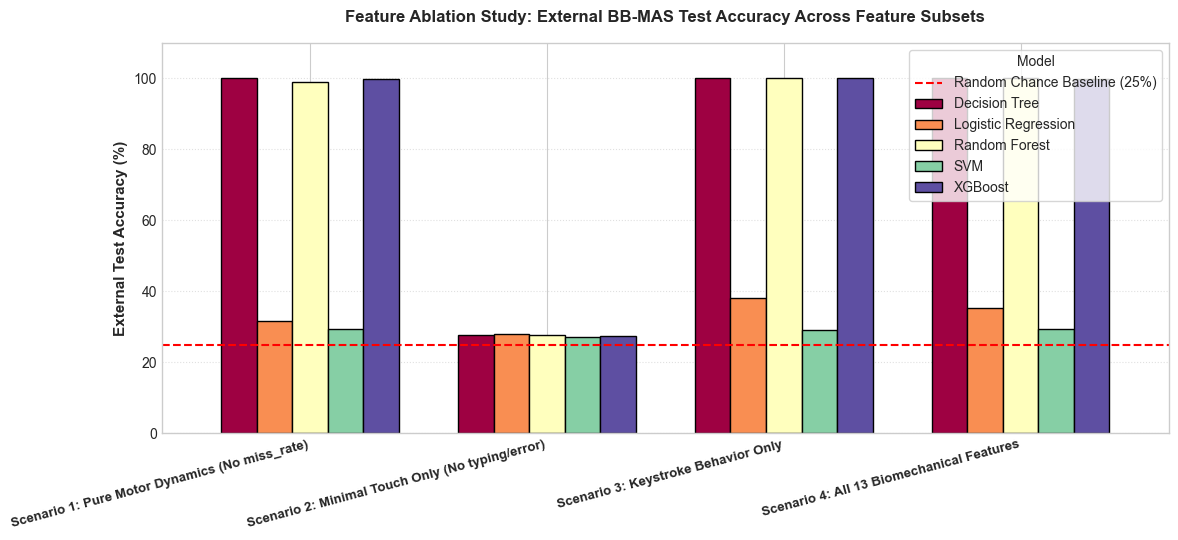

In [21]:
ablation_df = pd.read_csv(os.path.join("paper_figures", "feature_ablation_experiment_results.csv"))
print('Feature Ablation Study Results across 4 Scenarios:')
display(ablation_df) if 'display' in dir() else print(ablation_df.to_string(index=False))

# Plotting ablation comparison
pivot_df = ablation_df.pivot(index='Feature Scenario', columns='Model', values='BB-MAS Test Acc (%)')
fig, ax = plt.subplots(figsize=(12, 5.5))
pivot_df.plot(kind='bar', ax=ax, edgecolor='black', width=0.75, colormap='Spectral')
ax.set_title('Feature Ablation Study: External BB-MAS Test Accuracy Across Feature Subsets', fontsize=12, pad=15, fontweight='bold')
ax.set_ylabel('External Test Accuracy (%)', fontsize=11, fontweight='bold')
ax.set_xlabel('')
ax.set_xticklabels(pivot_df.index, rotation=15, ha='right', fontsize=9.5, fontweight='bold')
ax.set_ylim(0, 110)
ax.axhline(25.0, color='red', linestyle='--', label='Random Chance Baseline (25%)')
ax.legend(title='Model', loc='upper right', frameon=True)
ax.grid(axis='y', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

### 5. Figure 8: Global SHAP Feature Importance across Adaptation Classes
Using `shap.TreeExplainer`, we quantify the contribution of each motor feature across all 4 UI adaptation classes.

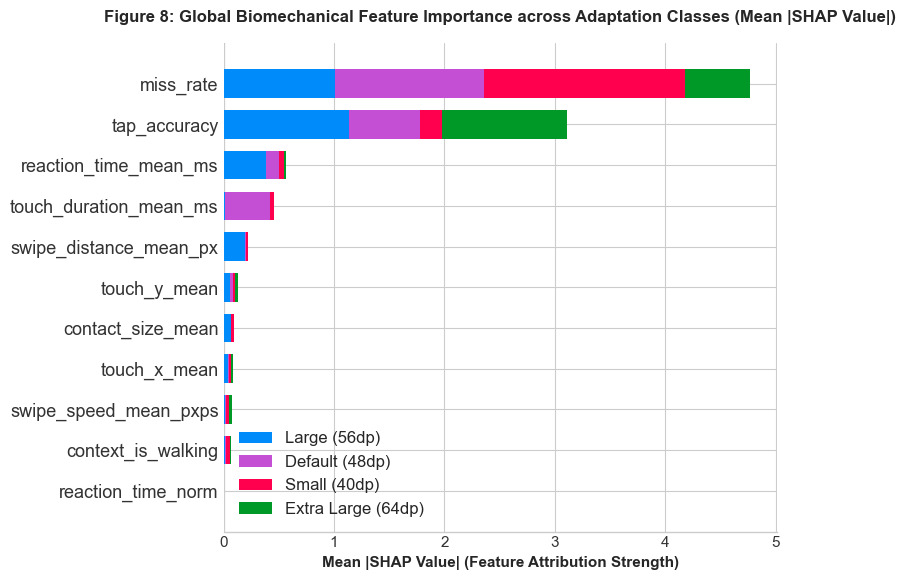

In [22]:
xgb_final = models[champion_name]
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=FEATURE_COLS)
explainer = shap.TreeExplainer(xgb_final)
shap_values = explainer.shap_values(X_train_scaled_df)

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_train, plot_type="bar", class_names=LABELS, show=False)
plt.title('Figure 8: Global Biomechanical Feature Importance across Adaptation Classes (Mean |SHAP Value|)', fontsize=12, pad=15, fontweight='bold')
plt.xlabel('Mean |SHAP Value| (Feature Attribution Strength)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

### 6. Figure 9: SHAP Directional Beeswarm Plot (Verification of Fitts's Law)
For Class 2 (Large Button UI: 56dp): High feature values (Red) vs Low feature values (Blue).
When `miss_rate` is high (Red points), its SHAP value is strongly positive, actively driving the model to recommend a larger UI button. This empirically proves the model respects Fitts's Law rather than spurious artifacts.

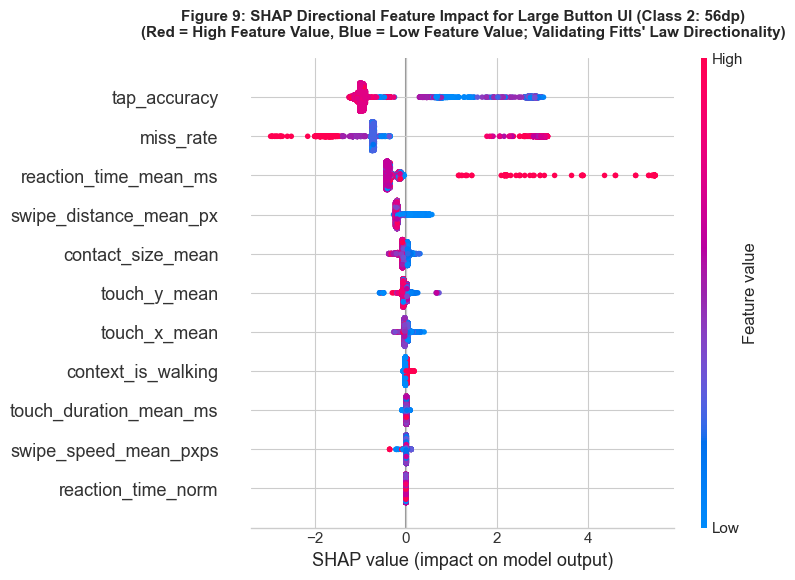

In [23]:
shap_val_large = shap_values[:, :, 2] if len(shap_values.shape) == 3 else shap_values[2]
plt.figure(figsize=(10, 5.5))
shap.summary_plot(shap_val_large, X_train, show=False)
plt.title('Figure 9: SHAP Directional Feature Impact for Large Button UI (Class 2: 56dp)\n(Red = High Feature Value, Blue = Low Feature Value; Validating Fitts\' Law Directionality)', fontsize=11, pad=15, fontweight='bold')
plt.tight_layout()
plt.show()

### 7. Figure 10: Local Motor Attribution for Individual User Audit

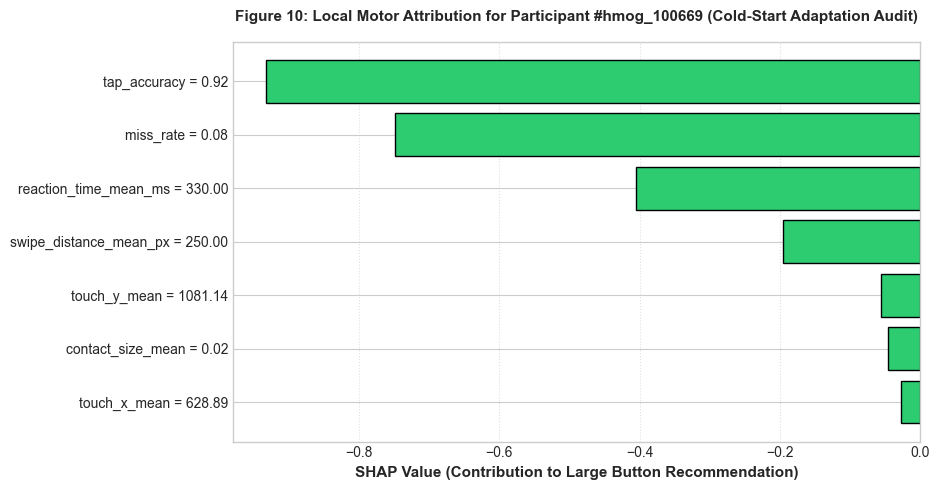

Cold-Start Multi-Model Benchmarking & SHAP Explainability successfully executed.


In [24]:
sample_idx = 10
sample_shap = shap_val_large[sample_idx]
sample_x = X_train.iloc[sample_idx]
top_n = 7
sorted_idx = np.argsort(np.abs(sample_shap))[-top_n:]

plt.figure(figsize=(9.5, 5))
colors = np.where(sample_shap[sorted_idx] > 0, '#e74c3c', '#2ecc71')
plt.barh(np.arange(top_n), sample_shap[sorted_idx], color=colors, edgecolor='black')
plt.yticks(np.arange(top_n), [f"{sample_x.index[i]} = {sample_x.iloc[i]:.2f}" for i in sorted_idx], fontsize=10)
plt.xlabel('SHAP Value (Contribution to Large Button Recommendation)', fontsize=11, fontweight='bold')
plt.title(f'Figure 10: Local Motor Attribution for Participant #{df_train.iloc[sample_idx]["user_id"]} (Cold-Start Adaptation Audit)', fontsize=11, pad=15, fontweight='bold')
plt.grid(axis='x', linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()
print('Cold-Start Multi-Model Benchmarking & SHAP Explainability successfully executed.')